# Otsu manual com NumPy 

In [5]:
import sys
from pathlib import Path

# O kernel inicia na pasta DESTE caderno — localiza a raiz do projeto:
RAIZ = Path.cwd()
if not (RAIZ / "src" / "leitura.py").exists():
    RAIZ = RAIZ.parent          # kernel começou dentro de notebooks/
sys.path.insert(0, str(RAIZ))   # raiz no path -> 'from src...' funciona

# Imports padrão de todos os cadernos:
from src.leitura import (PASTA_IMAGENS, PASTA_RESULTADOS, carregar_imagem,
                         nome_da_mascara, criar_pastas_resultados, auditar_base)
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("raiz do projeto:", RAIZ)

raiz do projeto: /home/isadora/Documentos/ProcessIMg


In [6]:
from src.preprocessamento import para_cinza, histograma
from src.segmentacao import otsu

In [7]:
# validação oficial: t* da nossa implementação vs t* do OpenCV, em 5 imagens
nomes = ["ISIC_0010206.jpg", "ISIC_0012940.jpg",
         "ISIC_0010104.jpg", "ISIC_0013695.jpg", "PH2_IMD057.bmp"]

print(f"{'imagem':<16} {'t_manual':>8} {'t_cv2':>6} {'igual?':>7} {'% máscara (>t)':>15}")
for nome in nomes:
    cinza = para_cinza(carregar_imagem(PASTA_IMAGENS / nome))
    t_manual = otsu(cinza)
    t_cv2, _ = cv2.threshold(cinza, 0, 255, cv2.THRESH_OTSU)
    frac = (cinza > t_manual).mean() * 100
    print(f"{Path(nome).stem:<16} {t_manual:>8} {int(t_cv2):>6} {str(t_manual == int(t_cv2)):>7} {frac:>14.1f}%")

imagem           t_manual  t_cv2  igual?  % máscara (>t)
ISIC_0010206          168    168    True           94.1%
ISIC_0012940          169    169    True           55.8%
ISIC_0010104          204    204    True           67.6%
ISIC_0013695           96     96    True           98.2%
PH2_IMD057            123    123    True           54.1%


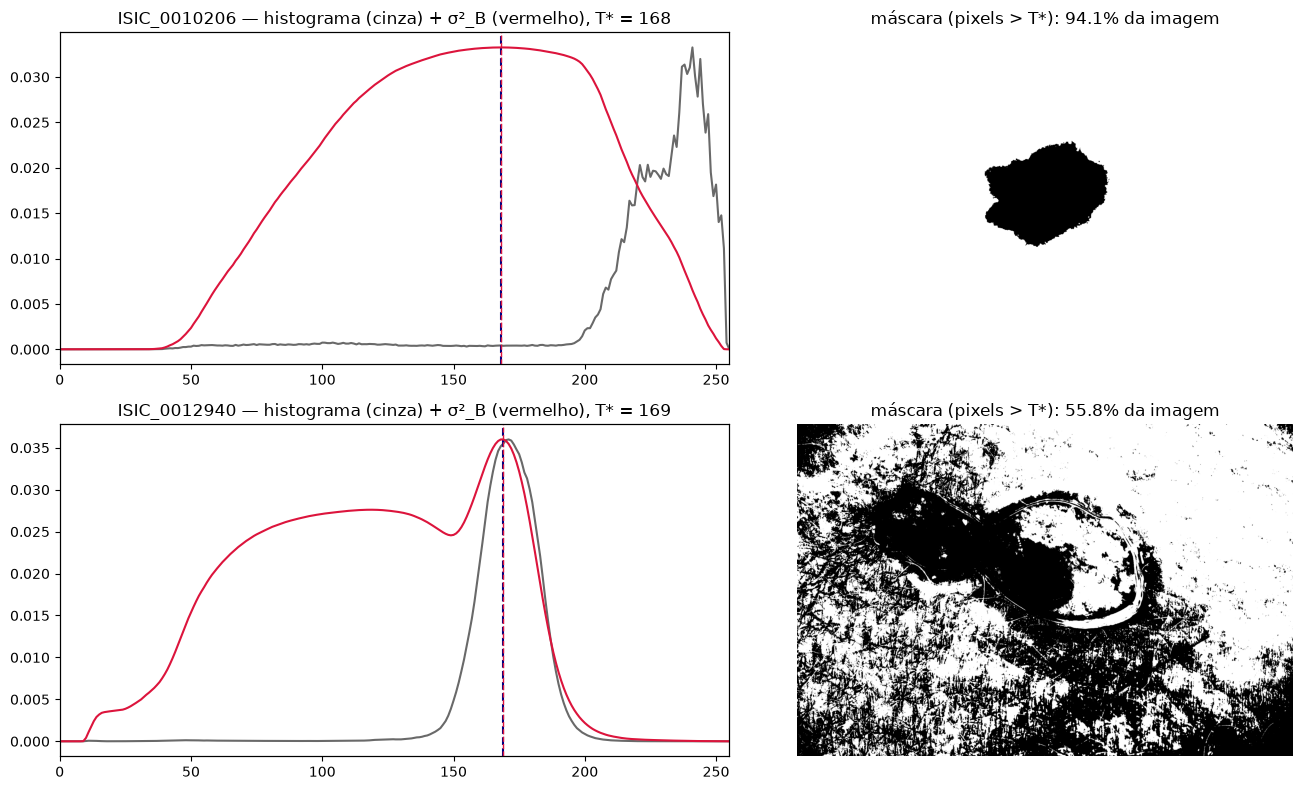

In [8]:
# o teste da previsão do Passo 8: histograma + curva de sigma_B + máscara resultante
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for i, nome in enumerate(["ISIC_0010206.jpg", "ISIC_0012940.jpg"]):
    cinza = para_cinza(carregar_imagem(PASTA_IMAGENS / nome))
    nome_curto = Path(nome).stem
    hist = histograma(cinza, normalizar=True)
    t = otsu(cinza)

    niveis = np.arange(256)
    omega = np.cumsum(hist)
    mu_acum = np.cumsum(niveis * hist)
    mu_global = niveis @ hist
    mu_e = mu_acum / np.maximum(omega, 1e-12)
    mu_c = (mu_global - mu_acum) / np.maximum(1 - omega, 1e-12)
    sigma_b = omega * (1 - omega) * (mu_e - mu_c) ** 2

    axes[i, 0].plot(hist, color="dimgray")
    ax_t = axes[i, 0].twinx()
    ax_t.plot(sigma_b, color="crimson")
    ax_t.axvline(t, color="crimson", ls="--", lw=1)
    ax_t.set_yticks([])
    axes[i, 0].axvline(t, color="navy", ls="--")
    axes[i, 0].set_title(f"{nome_curto} — histograma (cinza) + σ²_B (vermelho), T* = {t}")
    axes[i, 0].set_xlim(0, 255)

    msk = (cinza > t).astype(np.uint8) * 255   # polaridade padrão: claros brancos
    frac = msk.mean() / 255
    axes[i, 1].imshow(msk, cmap="gray")
    axes[i, 1].set_title(f"máscara (pixels > T*): {frac*100:.1f}% da imagem")
    axes[i, 1].axis("off")

fig.tight_layout()
fig.savefig(PASTA_RESULTADOS / "segmentadas" / "otsu_previsao.png", bbox_inches="tight", dpi=150)
plt.show()
plt.close(fig)